## Ronne-Filchner Ice Shelf Attempt 2

Goal is to capture both the export (northward) and import (southward) current.
F04 transect mentioned in [this study by Daae et al., 2019](https://journals.ametsoc.org/view/journals/phoc/49/1/jpo-d-18-0093.1.xml#bib24) and first investigated in [this study by Foldvik et al, 2004](https://agupubs.onlinelibrary.wiley.com/doi/10.1029/2003JC002008) show that there are dense shelf overflows along the transect.

In [1]:
#Packages 
import numpy as np
import xarray as xr
import cmocean.cm as cmo
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import mosaic
import geojson
import os
import xeos
from xgcm import Grid
from datetime import datetime
from mpas_tools.ocean.depth import add_zmid
from mpas_tools.ocean.depth import compute_zmid
from mpas_tools.mesh.mask import compute_mpas_region_masks
from geometric_features import read_feature_collection

%load_ext autoreload
%autoreload 2
import mpasregions.sections as mps

plt.rcdefaults()

# 2. Apply the local, lightweight sans-serif computer modern configurations
plt.rcParams.update({
    "text.usetex": False,                                 # Disable external LaTeX requirement
    "font.family": "sans-serif",
    "font.sans-serif": ["Computer Modern Sans Serif", "cmss10", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",                       # Safest built-in engine for sans-serif math
    "axes.unicode_minus": False,
})

In [2]:
def rename_time_avg_vars(avg_ds_output):
    old_name_array = []
    new_name_array = []
    
    for i in avg_ds_output.data_vars:
        old_name_array.append(i)
        if 'timeMonthly' in i:
            new_name = i.replace('timeMonthly_avg_' , '')
            if 'Tracer' in new_name:
                new_name = new_name.split('_')[1]
        else:
            new_name = i                
        new_name_array.append(new_name)
    
    new_name_dict = dict(zip(old_name_array, new_name_array))

    return new_name_dict

def find_var_in_ds(ds, var_string):
    for i in ds.data_vars:
        if var_string in i:
            print(i)

def var_to_depth_coords(ds, variable):
    # target coords
    grid_nVertLevels = Grid(ds, coords={'Z' : {'center' : 'nVertLevels', 'outer' : 'nVertLevelsP1'}}, 
                                padding = 'extend', 
                                autoparse_metadata=False)
    
    # then transform the variable we are interested in to refBottomDepth
    depth_variable = grid_nVertLevels.transform(variable,
                               'Z',
                               target = ds.refBottomDepth,
                               method = 'linear',
                               target_data = ds.zMid)
    
    # then swap_dims to get refBottomDepth as a coordinate
    refBottomDepth_variable = depth_variable.swap_dims({'nVertLevels' : 'refBottomDepth' })

    return refBottomDepth_variable

def circular_polar_map():
    # Make the polar map circular
    theta = np.linspace(0, 2 * np.pi, 100)
    center = [0.5, 0.5]
    radius = 0.5
    
    verts = np.vstack([
        np.sin(theta) * radius + center[0],
        np.cos(theta) * radius + center[1]
    ]).T
    
    circle = mpath.Path(verts)
    return verts, circle

def plot_stereo(data_variable, **kwargs):
    stereo_projection = ccrs.SouthPolarStereo()
    stereo_transform = ccrs.PlateCarree()
    stereo_descriptor = mosaic.Descriptor(mesh, stereo_projection, stereo_transform)
    
    fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True, subplot_kw={'projection' : stereo_projection})
    
    c = mosaic.polypcolor(ax, stereo_descriptor, data_variable, **kwargs)
    # mosaic.coastlines(ax, stereo_descriptor, color = 'gray')
    
    # Focus on Southern Ocean
    ax.set_extent(
        [-180, 180, -90, -60],
        crs=ccrs.PlateCarree()
    )
    # Make the polar map circular
    theta = np.linspace(0, 2 * np.pi, 100)
    center = [0.5, 0.5]
    radius = 0.5
    
    verts = np.vstack([
        np.sin(theta) * radius + center[0],
        np.cos(theta) * radius + center[1]
    ]).T
    
    circle = mpath.Path(verts)
    
    ax.set_boundary(circle, transform=ax.transAxes)
    gl = ax.gridlines(linewidth=0.75,color="black",alpha=0.5,linestyle="dotted",draw_labels=True)
    fig.colorbar(c, ax=ax, orientation = 'vertical')

## define a function to plot this
def pcolormesh_plot(ds_single_transect_insideCells, on_nVertLevelsP1=False):
    """
    Function to plot based on nCells, not nEdges...
    """
    
    if on_nVertLevelsP1 == False:
        # for pcolormesh, the dimensions of x-array and y-array must be size (N+1, M+1) where the color-array is of size (N,M)
        
        ## X ARRAY (nCells)
        # for nVertLevels = M+1, we can just use broadcast_like z_P1, which already has a length of M+1
        x_Mp1 = ds_single_transect_insideCells.transect_cellsInsideOrdered.broadcast_like(ds_single_transect_insideCells.z_P1)
        
        # for nCells = N, we need to add an additional row
        # we need to expand nCells to a size of 127 = N+1 to make a pcolormesh
        # add to the existing x data
        x_Np1Mp1 = xr.concat([x_Mp1, x_Mp1.isel(nCells=-1)+1], dim='nCells')
        
        # then we need to stagger the actual nCell values to represent the "edges" of the nCells
        x_Np1Mp1_outer = x_Np1Mp1 + 0.5
        
        ## Y ARRAY (z_P1)
        # for nVertLevels = M+1, we can use z_P1 instead (again). This also ensures that we are already on outer coords
        y_Mp1_outer = ds_single_transect_insideCells.z_P1.transpose('nCells','nVertLevelsP1')
        
        # add one additional nCell
        y_Np1Mp1_outer = xr.concat([y_Mp1_outer, y_Mp1_outer.isel(nCells=-1) + 1], dim='nCells')
        
        # ffill along the nVertLevels dimension
        y_Np1Mp1_outer = y_Np1Mp1_outer.ffill(dim='nVertLevelsP1')

    else:
        # for pcolormesh, the dimensions of x-array and y-array must be size (N+1, M+1) where the color-array is of size (N,M)
        # nCells = N, nVertLevels = M+1
        
        ## X ARRAY (nCells)
        # we use nVertLevelsP1 instead (since the variable is located on P1 levels)
        # add one additional vertical level
        x = ds_single_transect_insideCells.transect_cellsInsideOrdered.broadcast_like(ds_single_transect_insideCells.z_P1)
        x_Mp1 = xr.concat([x, x.isel(nVertLevelsP1=-1)], dim='nVertLevelsP1')
        
        # we add one additional nCell
        x_Np1Mp1 = xr.concat([x_Mp1, x_Mp1.isel(nCells=-1)+1], dim='nCells')
        
        # convert x_Np1Mp1 to outer values (provide nCell edges for pcolormesh plotting)
        x_Np1Mp1_outer = x_Np1Mp1 + 0.5
        
        ## Y ARRAY (nVertLevels)
        # zMid is the "outer" coord for z_P1
        y_outer = ds_single_transect_insideCells.zMid.transpose('nCells','nVertLevels')
        # add two additional outer vertical levels (interpolate the first and last points) 
        y_Mp1_outer = xr.concat([y_outer[:,1] - ((y_outer[:,1] - y_outer[:,0])/2), 
                           y_outer, 
                           y_outer[:,-1] + ((y_outer[:,-1] - y_outer[:,-2])/2)], dim = 'nVertLevels')
        
        # add one additioanl nCell
        y_Np1Mp1_outer = xr.concat([y_Mp1_outer, y_Mp1_outer.isel(nCells=-1)], dim='nCells')
        
        # ffill along the nVertLevels dimension
        y_Np1Mp1_outer = y_Np1Mp1_outer.ffill(dim='nVertLevels')

    return x_Np1Mp1_outer, y_Np1Mp1_outer

# # define a function to plot nEdges
# def pcolormesh_plot(ds_single_transect_insideCells, on_nVertLevelsP1=False)
#     """
#     Function to plot based on nEdges and depth, not nVertLevels
#     """

#     if on_nVertLevlsP1 == False:


In [3]:
month='Sept'
yr = '0200-09-01'
sorrm_filepath = '/global/cfs/cdirs/m5260/kuyeda/20260318.v3.SORRME3r3.CRYO2010.bluepulse-beta1-dvd.perlmutter/run/'

# this is hist output
# which is snapshots?

# OPEN OCEAN AVG FILE
ocean_avg_ds_output = xr.open_dataset(sorrm_filepath + f'20260318.v3.SORRME3r3.CRYO2010.bluepulse-beta1-dvd.perlmutter.mpaso.hist.am.timeSeriesStatsMonthly.{yr}.nc')
                                                        
# OPEN ICE AVG FILE
ice_avg_ds_output = xr.open_dataset(sorrm_filepath + f'20260318.v3.SORRME3r3.CRYO2010.bluepulse-beta1-dvd.perlmutter.mpassi.hist.am.timeSeriesStatsMonthly.{yr}.nc')

# select just the ice variables that we want
ice_avg_ds_output = ice_avg_ds_output[['timeMonthly_avg_iceAreaCell',
                                       'timeMonthly_avg_iceVolumeCell',
                                       'timeMonthly_avg_frazilFormation',
                                       'timeMonthly_avg_surfaceIceMelt',
                                       'timeMonthly_avg_basalIceMelt',
                                       'timeMonthly_avg_lateralIceMelt']]

# combine ice and ocean files into one dataset
avg_ds_output = xr.merge([ocean_avg_ds_output, ice_avg_ds_output])

# OPEN SNAPSHOTS OCEAN FILE
# ss_ds_output = xr.open_dataset(sorrm_filepath + f'20260318.v3.SORRME3r3.CRYO2010.bluepulse-beta1-dvd.perlmutter.mpaso.hist.{yr}.nc')
                                                

/tmp/ipykernel_212375/2893904018.py:9: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's default way of encoding timedelta64 values. To continue decoding timedeltas based on the presence of a timedelta-like units attribute, users will need to explicitly opt-in by passing True or CFTimedeltaCoder(decode_via_units=True) to decode_timedelta. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  ocean_avg_ds_output = xr.open_dataset(sorrm_filepath + f'20260318.v3.SORRME3r3.CRYO2010.bluepulse-beta1-dvd.perlmutter.mpaso.hist.am.timeSeriesStatsMonthly.{yr}.nc')
/tmp/ipykernel_212375/2893904018.py:12: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely

In [4]:
# OPEN MESH & DS_OUTPUT FILES, FORMAT

# MESH (I.E., RESTART INITIAL CONDITION)
mesh = xr.open_dataset(sorrm_filepath + '20260520.v3.SORRME3r3.CRYO2010.bluepulse-control.chrysalis.mpaso.rst.0200-01-01_00000.nc')
# ice_mesh = xr.open_dataset(sorrm_filepath + '20260520.v3.SORRME3r3.CRYO2010.bluepulse-control.chrysalis.mpassi.rst.0200-01-01_00000.nc')

mesh = mesh.assign_coords({
"VertexID": xr.DataArray(mesh.indexToVertexID, dims=('nVertices',)),
})


# set up descriptor for plotting 
# # set up mesh to apply polypcolor
mesh.attrs['is_periodic'] = 'YES'
mesh.attrs['x_period'] =  360
mesh.attrs['y_period'] = 0.0

# FORMAT AVG_DS_OUTPUT FILE
ds = mps.add_grid_info_coords(mesh,avg_ds_output)
ds = xr.merge([ds, mesh.isel(Time=0)[['landIcePressure',
                                 'landIceDraft',
                                 'landIceFraction',
                                 'landIceMask',
                                 'landIceFloatingMask',
                                 'landIceFloatingFraction',
                                 'seaIcePressure']]])
ds['lonCell'] = ds.lonCell 
ds['lonEdge'] = ds.lonEdge
ds['lonVertex'] = ds.lonVertex 

# FORMAT AVG_DS_OUTPUT FROM SORRM 
drop_var_names = ['avgValue', 'Stats', 'min', 'max']

dropped_vars = [
    item for item in list(ds.data_vars)
    if any(var_name in item for var_name in drop_var_names)
]

ds = ds.drop_vars(dropped_vars)
new_name_dict = rename_time_avg_vars(ds)
ds = ds.rename(new_name_dict)

ds_grid = Grid(ds, coords={'Z' : {'center' : 'nVertLevels', 'outer' : 'nVertLevelsP1'}},
           padding = 'extend', 
           autoparse_metadata = False)

ds['chiPhyVerTemp_center'] = ds_grid.interp(ds.chiPhyVerTemp, 'Z' , padding = 'extend')
ds['chiPhyVerSalt_center'] = ds_grid.interp(ds.chiPhyVerSalt, 'Z', padding = 'extend')
ds['vertDiff_center'] = ds_grid.interp(ds.vertDiffTopOfCell, 'Z', padding = 'extend')

# interpolate salinity onto nVertLevelsP1
# ffill (good practice but not applicable here because no bathymetry)
ds['salinity'] = ds.salinity.ffill(dim= 'nVertLevels', limit = 2)
ds['salinity'] = ds.salinity.bfill(dim= 'nVertLevels', limit = 2)

ds['salinity_P1'] = ds_grid.interp(ds.salinity, 'Z', padding = 'extend')

# add depth datavariable
ds['zMid'] = - compute_zmid(ds.bottomDepth, ds.maxLevelCell, ds.layerThickness)

# create a grid for interpolation & transformation
grid_nVertLevels = Grid(ds, coords={'Z' : {'center' : 'nVertLevels', 'outer' : 'nVertLevelsP1'}}, 
                                padding = 'extend', 
                                autoparse_metadata=False)

# add a zEdge variable
ds['z_P1'] = grid_nVertLevels.interp(ds.zMid, 'Z', padding = 'extend')
ds['z_P1'] = ds.z_P1.transpose('Time','nCells','nVertLevelsP1')
ds['z_P1'][:,:,0] = ds.z_P1[:,:,0] - ((ds.z_P1[:,:,1] - ds.z_P1[:,:,0])/2)
ds['z_P1'][:,:,-1] = ds.z_P1[:,:,-1] + ((ds.z_P1[:,:,-1] - ds.z_P1[:,:,-2])/2)

# ^^ have to manually add the first and last points, since they should extend beyond the zMid points 

# add a refBottomDepth variable that sits on nVertLevels
ds['refBottomDepth_P1'] = grid_nVertLevels.interp(ds.refBottomDepth, 'Z', padding = 'extend')
ds['refBottomDepth_P1'][0] = ds.refBottomDepth_P1[0] - ((ds.refBottomDepth_P1[1] - ds.refBottomDepth_P1[0])/2)
ds['refBottomDepth_P1'][-1] = ds.refBottomDepth_P1[-1] - ((ds.refBottomDepth_P1[-1] - ds.refBottomDepth_P1[-2])/2)

ds = ds.assign_coords({'refBottomDepth' : ds.refBottomDepth, 'refBottomDepth_P1' : ds.refBottomDepth_P1})

# calculate potential density reference to 2000m
eos = xeos.from_model('MPAS-Ocean', 'jm')
sigma2_jm = eos.rho(ds.temperature, ds.salinity, 2000.0) - 1000.0
sigma2_jm.attrs['long_name'] = r'$\sigma_2$ (jm)'
sigma2_jm.attrs['units'] = 'kg m-3'
ds['sigma_2'] = sigma2_jm

## ^^ note that MPAS-Ocean (not Omega) uses potential temp and practical salinity, which is what is calculated by the model
## BUT in Omega, conservative temperature and absolute salinity are used instead 
# (and are therefore output as "temperature" and "salinity" datavariables)

# calculate pressure using xeos
ds['pressure'] = xeos.conventions.pressure_from_depth(ds.zMid)

# SET UP PLOTTING
# set up plotting descriptor
projection = ccrs.PlateCarree(central_longitude = 180)
descriptor = mosaic.Descriptor(mesh, projection, transform = ccrs.PlateCarree(), use_latlon=True)

# set up stereographic projections
stereo_projection = ccrs.SouthPolarStereo()
stereo_transform = ccrs.PlateCarree()
stereo_descriptor = mosaic.Descriptor(mesh, stereo_projection, stereo_transform)

"""
# FORMAT SNAPSHOTS FROM SORRM
# 9/2/26 --> currently commented out b/c no salinity datavariable
# snapshots at every timestep (dt = ? mins)
# ss_ds_output = xr.open_dataset(filepath + f'{sim_res}_channel_output.nc' + suffix,decode_times=False)

# assign nVertLevelsP1 coordinates
ss_ds_output = ss_ds_output.assign_coords({'nVertLevelsP1' : avg_ds_output.nVertLevelsP1})

# interpolate salinity onto nVertLevelsP1
ss_ds_grid = Grid(ss_ds_output, coords={'Z' : {'center' : 'nVertLevels', 'outer' : 'nVertLevelsP1'}},
                   padding = 'extend', 
                   autoparse_metadata = False)

# ffill (good practice but not applicable here because no bathymetry)
ss_ds_output['salinity'] = ss_ds_output.salinity.ffill(dim= 'nVertLevels', limit = 2)
ss_ds_output['salinity'] = ss_ds_output.salinity.bfill(dim= 'nVertLevels', limit = 2)

ss_ds_output['salinity_P1'] = ss_ds_grid.interp(ss_ds_output.salinity, 'Z', padding = 'extend')
""";

In [5]:
bottom_cell_density = ds.sigma_2.isel(nVertLevels = ds.maxLevelCell -1, Time=0)
bottom_depth = ds.zMid.isel(nVertLevels=ds.maxLevelCell -1, Time=0)

In [6]:
bottom_depth

<xarray.DataArray 'zMid' (nCells: 807630)> Size: 6MB
array([2043.8632315 , 1580.21864829, 1150.70369133, ...,   23.82297282,
         27.92313708,   19.5022436 ], shape=(807630,))
Coordinates: (12/18)
    Time                      object 8B 0200-09-16 00:00:00
    latCell                   (nCells) float64 6MB -1.458 -1.457 ... 0.6004
    lonCell                   (nCells) float64 6MB 5.223 5.239 ... 2.348 2.342
    xCell                     (nCells) float64 6MB 3.515e+05 ... -3.664e+06
    yCell                     (nCells) float64 6MB -6.277e+05 ... 3.77e+06
    zCell                     (nCells) float64 6MB -6.33e+06 ... 3.6e+06
    ...                        ...
    minLevelCell              (nCells) int32 3MB 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1
    maxLevelCell              (nCells) int32 3MB 5 5 5 11 22 5 ... 15 10 9 10 8
    refBottomDepth            (nCells) float64 6MB 11.92 11.92 ... 30.09 21.89
    restingThickness          (nCells) float64 6MB 413.0 302.6 ... 4.271 2.488
    vertCoordMovementWeights  (nCells) float64 6MB 1.0 1.0 1.0 ... 1.0 1.0 1.0
    simulationStartTime       |S64 64B b'0001-01-01_00:00:00'
Dimensions without coordinates: nCells

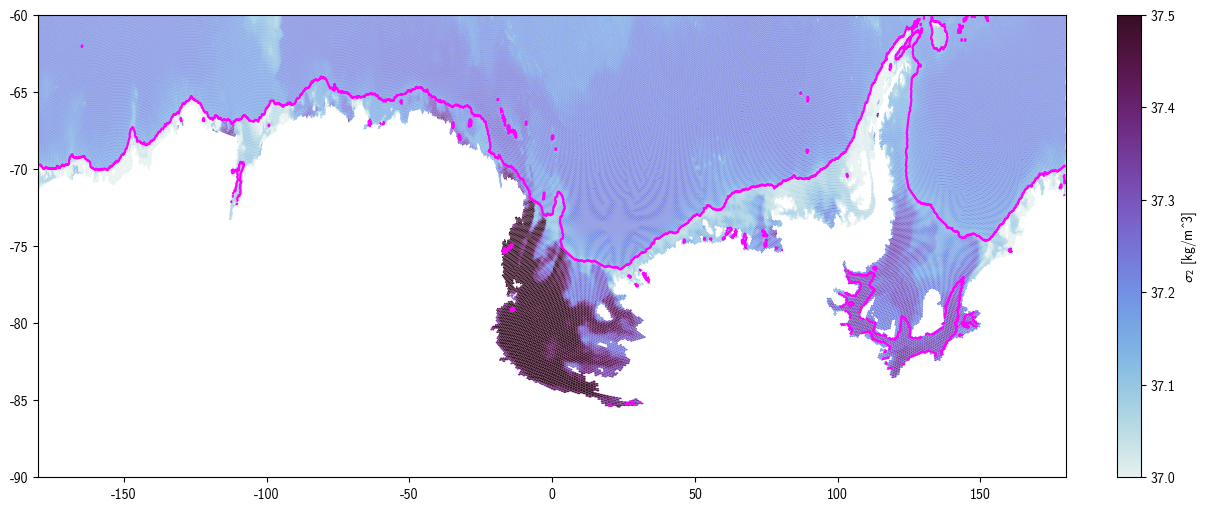

In [7]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True, figsize=(12,5))

c = mosaic.polypcolor(ax, descriptor, bottom_cell_density, cmap = 'cmo.dense', vmin=37, vmax=37.5)
d = mosaic.contour(ax, descriptor, bottom_depth, levels=[0,1000], colors=['white','magenta'])

ax.set_ylim(-90,-60)

fig.colorbar(c, ax=ax, label=r'$\sigma_2$ [kg/m^3]')

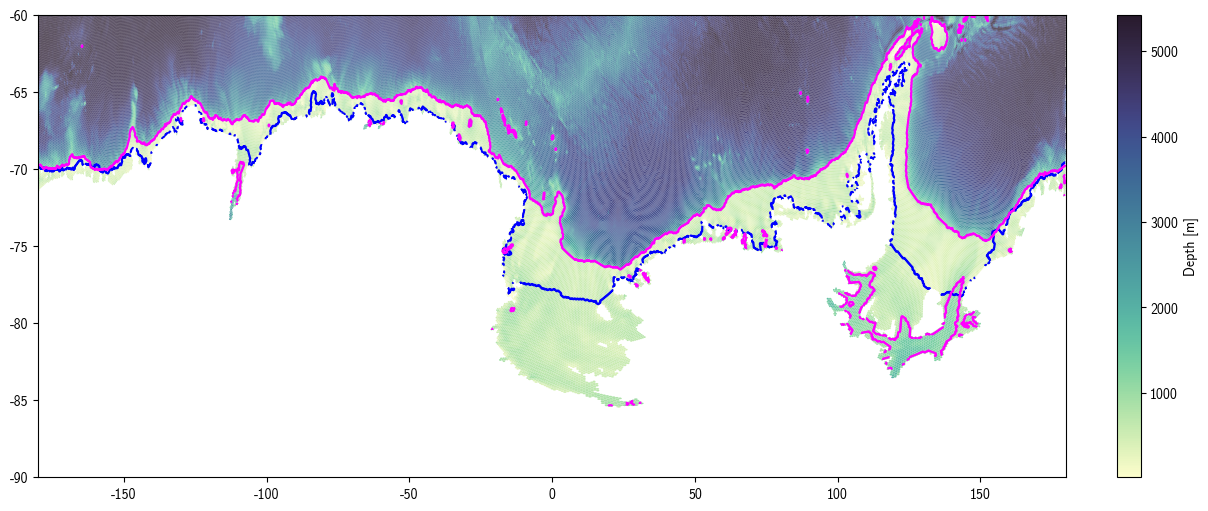

In [8]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True, figsize=(12,5))

c = mosaic.contour(ax, descriptor, ds.landIceFraction, levels=[0.25,1], colors=['blue','white'])
d = mosaic.contour(ax, descriptor, bottom_depth, levels=[0,1000], colors=['white','magenta'])
e = mosaic.polypcolor(ax, descriptor, bottom_depth,cmap = 'cmo.deep')

ax.set_ylim(-90,-60)

fig.colorbar(e, ax=ax, label=r'Depth [m]')

# Transect-building

## transect from F04
Table 1 from F04.

|Latitude|Longitude|
|---| ---|
|-74.07 | -39.18|
|-74.08 | -39.23|
|-74.06 | -39.22|
|-74.26 | -39.24|
|-74.40 | -33.56|
|-74.23 | -37.39|
|-74.43 | -38.36|
|-74.04 | -35.45|
|-74.15 | -35.22|
|-74.40 | -33.56|
|-74.39 | -32.56|
|-74.40 | -34.00|
|-74.39 | -30.07|

In [9]:
# # based on the F04 transect
# # lats = np.array([-74.07, -74.08, -74.06, -74.26, -74.40, -74.23, -74.43, -74.04, -74.15, -74.40, -74.39, -74.40, -74.39])
# # lons = np.array([-39.18, -39.23, -39.22, -39.24, -33.56, -37.39, -38.36, -35.45, -35.22, -33.56, -32.56, -34.00, -30.07])

# # based on the potential density contours
# lons = np.array([120.5, 121, 123,   130, 137, 140, 139.5, 140, 143, 145.5, 146.5,   144, 143.5, 143.25, 143, 
#                      141, 135, 132, 127,   129,   126, 122, 120, 127.5, 125, 124.5, 120, 119]) - 180 
# lats = np.array([-85,   -83, -82, -81.5, -81, -80,   -79, -78, -77,   -76,   -75, -74.5,  -74.4, -74.5, -74.4, 
#                   -73.75, -72, -71, -70, -72.5,   -74, -76, -77,   -79, -80, -80.5, -82, -83])

# test_edges, test_verts = mps.calculate_transects_multiple_pts(lons, lats, ds)

In [10]:
path = './'
filename = 'Ronne_Filchner_Shelf_Break_SORRM_HR_test2'
geojson_file_name = 'SORRM HR Weddell Sea Region Shelf Break based on potential density contours'
tags = 'Southern Ocean'
author = 'Kaila Uyeda'

# across the shelf break
# based on the potential density contours
lons = np.array([120.5, 121, 123,   130, 137, 140, 139.5, 140, 143, 145.5, 146.5,   144, 143.5, 143.25, 143, 
                     141, 135, 132, 127,   129,   126, 122, 120, 127.5, 125, 124.5, 120, 119]) - 180 
lats = np.array([-85,   -83, -82, -81.5, -81, -80,   -79, -78, -77,   -76,   -75, -74.5,  -74.4, -74.5, -74.4, 
                  -73.75, -72, -71, -70, -72.5,   -74, -76, -77,   -79, -80, -80.5, -82, -83])

# ==========================
# These 3 functions are part of the open_transect_from_alg(ds, lats, lons, path, filename, geojson_file_name, tags, author) function

test_edges, test_verts = mps.calculate_transects_multiple_pts(lons, lats, ds)

test_verts_lats, test_verts_lons, dsMasks = mps.transect_from_alg_create_nc(test_verts, 
                                                                                ds, 
                                                                                path,
                                                                                filename, 
                                                                                geojson_file_name,
                                                                                tags, 
                                                                                author)

alg_edges, alg_vertices = mps.find_and_sort_transect_edges_and_vertices(ds,dsMasks)

# ==========================
edges = alg_edges
vertices = alg_vertices
mask = dsMasks

# ==========================

ds_transect_edges_nCells, ds_transect_edges = mps.format_transect_data(ds, edges)
print('calculate_velo_into_mask')
ds_transect_edges = mps.calculate_velo_into_mask(ds_transect_edges, ds, mask, edges, datavariable= 'normalVelocity')
print('calculate_transport_into_mask')
ds_transect_edges = mps.calculate_transport_into_mask(ds_transect_edges)

dsMasks = xr.open_dataset(f'./{filename}_transect_from_alg.nc')

# # attempt to find just a single transect
# export transect
ds_single_transect = ds_transect_edges.isel(nEdges = slice(300,664), Time=0)

# import transect
# ds_single_transect = ds_transect_edges.isel(nEdges = slice(0,300),Time=0)

# all cells
ds_single_transect = ds_transect_edges.isel(nEdges = slice(0,664), Time=0)

# Properly conduct a .where comparing the maxLevelCell to nVertLevels AND nVertLevelsP1
# select the datavariables that depend on nVertLevels
nVertLevels_datavariables = []
for i in ds_single_transect.data_vars:
    if 'nVertLevels' in ds_single_transect[i].dims:
        nVertLevels_datavariables.append(i)

# create a dataset with nVertLevels dimensions only
ds_single_transect_nVertLevels = ds_single_transect[nVertLevels_datavariables]

# conduct a .where to mask the values below maxLevelCell
ds_single_transect_nVertLevels_masked = ds_single_transect_nVertLevels.where(ds_single_transect.maxLevelCell > ds_single_transect_nVertLevels.nVertLevels)

# ============

# repeat for nVertLevelsP1 datavariables
# select the datavariables that depend on nVertLevelsP1

nVertLevelsP1_datavariables = []
for i in ds_single_transect.data_vars:
    if 'nVertLevelsP1' in ds_single_transect[i].dims:
        nVertLevelsP1_datavariables.append(i)

# create a dataset with nVertLevelsP1 dimensions only
ds_single_transect_nVertLevelsP1 = ds_single_transect[nVertLevelsP1_datavariables]

# conduct a .where to mask the values below maxlevelCell
ds_single_transect_nVertLevelsP1_masked = ds_single_transect_nVertLevelsP1.where(ds_single_transect.maxLevelCell > ds_single_transect_nVertLevelsP1.nVertLevelsP1)

# merge the two datasets
ds_single_transect_masked = xr.merge([ds_single_transect_nVertLevels_masked, ds_single_transect_nVertLevelsP1_masked])

broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
broken because reached end vertex
Ronne_Filchner_Shelf_Break_SORRM_HR_test2_transe

In [11]:
# # export transect
# ds_single_transect = ds_transect_edges.isel(nEdges = slice(300,664), Time=0)

# # import transect
# ds_single_transect = ds_transect_edges.isel(nEdges = slice(0,300),Time=0)

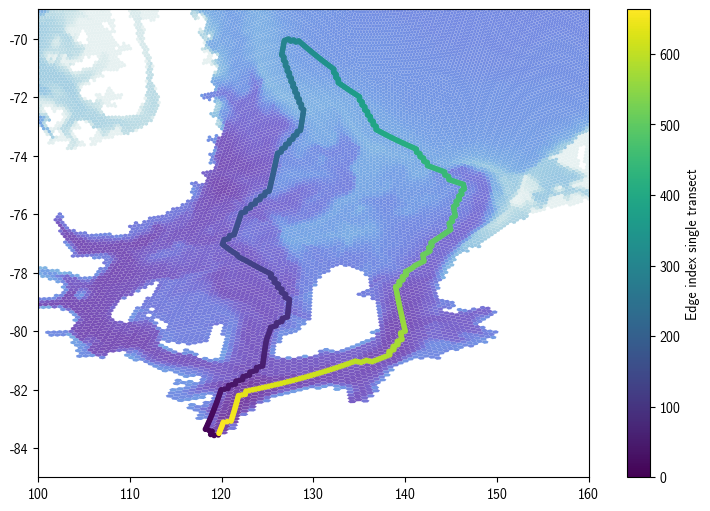

In [34]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True, figsize=(7,5))

mask = dsMasks.regionCellMasks.isel(nRegions = 0)

c = mosaic.polypcolor(ax, descriptor, bottom_cell_density, cmap = 'cmo.dense', vmin = 37, vmax=37.5)
a = ax.scatter(np.rad2deg(ds_single_transect_masked.lonEdge)-180, np.rad2deg(ds_single_transect_masked.latEdge), marker = '.',
              c = ds_single_transect_masked.transect_edgesOrdered)

ax.set_ylim(-85,-69)
ax.set_xlim(100,160)

fig.colorbar(a, ax=ax, label='Edge index single transect')

# fig.suptitle('Ronne-Filchner Ice Shelf (Weddell Sea) Transect \n J transect',fontsize=22)

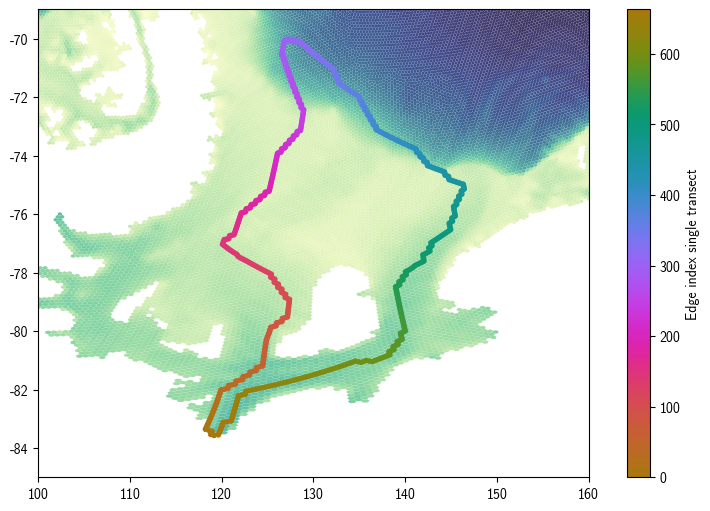

In [73]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True, figsize=(7,5))

mask = dsMasks.regionCellMasks.isel(nRegions = 0)

c = mosaic.polypcolor(ax, descriptor, bottom_depth, cmap = 'cmo.deep')
a = ax.scatter(np.rad2deg(ds_single_transect_masked.lonEdge)-180, np.rad2deg(ds_single_transect_masked.latEdge), marker = '.',
              c = ds_single_transect_masked.transect_edgesOrdered, cmap = 'cmo.phase')

ax.set_ylim(-85,-69)
ax.set_xlim(100,160)

fig.colorbar(a, ax=ax, label='Edge index single transect')

# fig.suptitle('Ronne-Filchner Ice Shelf (Weddell Sea) Transect \n J transect',fontsize=22)

In [61]:
# select all the cells inside the mask
mask = dsMasks
xr_cells_inside, ignore_xr_edges_inside, ignore_xr_vertices_inside = mps.xr_inside_mask_info(ds,mask)

# identify cells on transect_edges
# ds_single_transect = ds_transect_edges.isel(nEdges = slice(220,495), Time=0)

n_cellsOnTransect = ds_single_transect_masked.cellsOnEdge
xr_cellsOnTransect = mps.n_to_xr_idx(n_cellsOnTransect).transpose('nEdges','TWO')

# mask -1 values, which are NaNs
# xr_cellsOnTransect = xr_cellsOnTransect.where(xr_cellsOnTransect >= 0)

# for each xr_cellsOnTransect value, determine which cell is inside the mask
xr_transect_cells_inside_mask_ordered_raw = np.array([])
xr_transect_cells_outside_mask_ordered_raw = np.array([])

for i in range(0,len(xr_cellsOnTransect.nEdges)):
    # cell on transect edge that is inside mask
    xr_transect_cell_inside_mask = np.intersect1d(xr_cellsOnTransect[i], xr_cells_inside)

    # cell on transect edge that is outside mask
    xr_transect_cell_outside_mask = np.setxor1d(xr_cellsOnTransect[i], xr_transect_cell_inside_mask)

    # append the arrays
    xr_transect_cells_inside_mask_ordered_raw = np.append(xr_transect_cells_inside_mask_ordered_raw, xr_transect_cell_inside_mask)
    xr_transect_cells_outside_mask_ordered_raw = np.append(xr_transect_cells_outside_mask_ordered_raw, xr_transect_cell_outside_mask)

# remove any duplicate values in the array (e.g., if the cell was used once, do not use it again)
values, sorted_indices = np.unique(xr_transect_cells_inside_mask_ordered_raw, return_index = True)
xr_transect_cells_inside_mask_ordered = np.int32(xr_transect_cells_inside_mask_ordered_raw[np.sort([sorted_indices])].flatten())

values, sorted_indices = np.unique(xr_transect_cells_outside_mask_ordered_raw, return_index = True)
xr_transect_cells_outside_mask_ordered = np.int32(xr_transect_cells_outside_mask_ordered_raw[np.sort([sorted_indices])].flatten())


## identify transect inside cells
ds_single_transect_insideCells = ds.isel(nCells = xr_transect_cells_inside_mask_ordered, Time=0)

# assign order to nCells
ds_single_transect_insideCells = ds.isel(nCells = xr_transect_cells_inside_mask_ordered, Time=0)

# assign order to nCells
ds_single_transect_insideCells['transect_cellsInsideOrdered'] = xr.DataArray(np.arange(0,xr_transect_cells_inside_mask_ordered.size), dims = 'nCells')

x_center, y_center = pcolormesh_plot(ds_single_transect_insideCells)
x_P1, y_P1 = pcolormesh_plot(ds_single_transect_insideCells, on_nVertLevelsP1=True)

Text(0.5, 0.98, 'Sept Ronne-Filchner Ice Shelf')

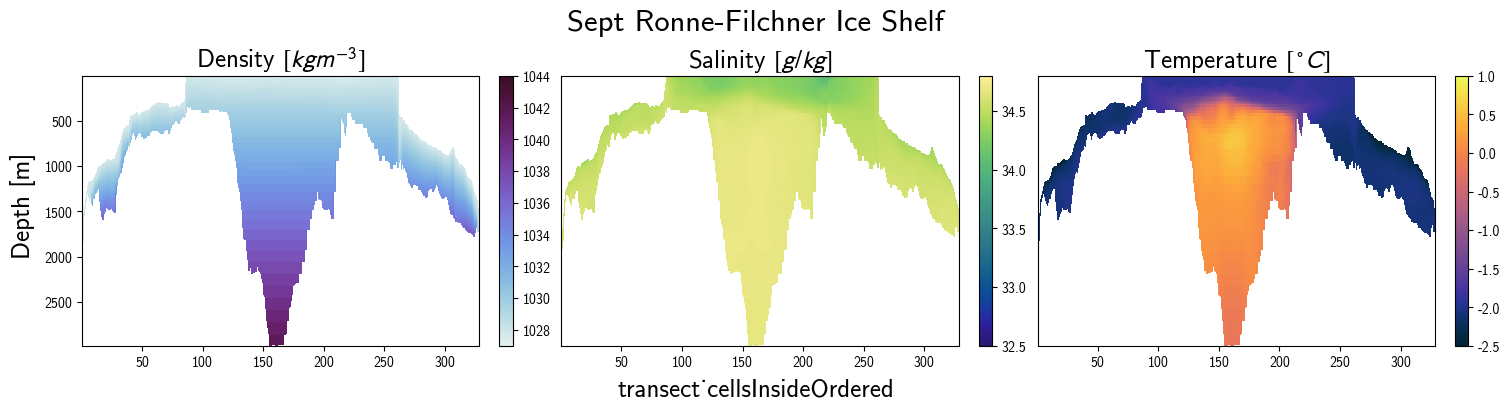

In [14]:
fig, ax = plt.subplots(nrows = 1, ncols = 3, constrained_layout=True, figsize = (15,4))

iceAreaCell = ds_single_transect_insideCells.iceAreaCell.swap_dims({'nCells' : 'transect_cellsInsideOrdered'})
transect_cellsInsideOrdered = ds_single_transect_insideCells.transect_cellsInsideOrdered

a = ax[0].pcolormesh(x_center, y_center, ds_single_transect_insideCells.density, cmap='cmo.dense',vmin=1027, vmax=1044)
ax[0].set_title(r'Density $[kg m^{-3}]$',fontsize=18)
fig.colorbar(a, ax=ax[0])

b = ax[1].pcolormesh(x_center, y_center, ds_single_transect_insideCells.salinity, cmap = 'cmo.haline', vmin=32.5, vmax=34.8)
ax[1].set_title(r'Salinity $[g/kg]$',fontsize=18)
ax[1].set_yticks([])
fig.colorbar(b, ax=ax[1])

c = ax[2].pcolormesh(x_center, y_center, ds_single_transect_insideCells.temperature, cmap = 'cmo.thermal', vmin=-2.5, vmax=1)
ax[2].set_title(r'Temperature $[^\circ C]$',fontsize=18)
ax[2].set_yticks([])
fig.colorbar(c, ax=ax[2])

for i in range(0,3):
    ax[i].invert_yaxis()

fig.supxlabel('transect_cellsInsideOrdered',fontsize=18)
fig.supylabel('Depth [m]',fontsize=18)
fig.suptitle(f'{month} Ronne-Filchner Ice Shelf',fontsize=22)

Text(0.5, 0.98, 'Sept Ronne-Filchner Ice Shelf')

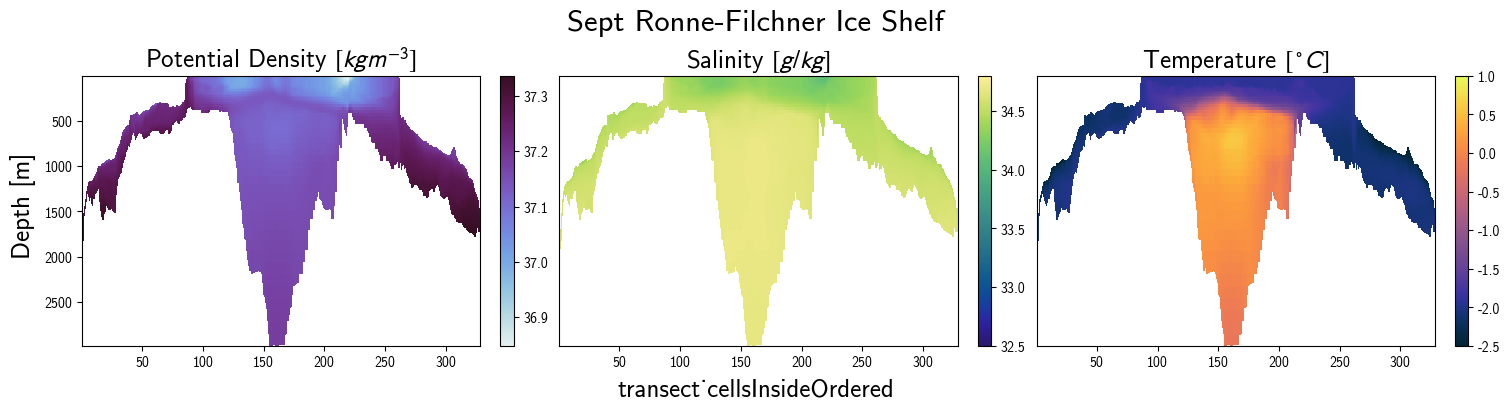

In [15]:
fig, ax = plt.subplots(nrows = 1, ncols = 3, constrained_layout=True, figsize = (15,4))

iceAreaCell = ds_single_transect_insideCells.iceAreaCell.swap_dims({'nCells' : 'transect_cellsInsideOrdered'})
transect_cellsInsideOrdered = ds_single_transect_insideCells.transect_cellsInsideOrdered

a = ax[0].pcolormesh(x_center, y_center, ds_single_transect_insideCells.sigma_2, cmap='cmo.dense')
ax[0].set_title(r'Potential Density $[kg m^{-3}]$',fontsize=18)
fig.colorbar(a, ax=ax[0])

b = ax[1].pcolormesh(x_center, y_center, ds_single_transect_insideCells.salinity, cmap = 'cmo.haline', vmin=32.5, vmax=34.8)
ax[1].set_title(r'Salinity $[g/kg]$',fontsize=18)
ax[1].set_yticks([])
fig.colorbar(b, ax=ax[1])

c = ax[2].pcolormesh(x_center, y_center, ds_single_transect_insideCells.temperature, cmap = 'cmo.thermal', vmin=-2.5, vmax=1)
ax[2].set_title(r'Temperature $[^\circ C]$',fontsize=18)
ax[2].set_yticks([])
fig.colorbar(c, ax=ax[2])

for i in range(0,3):
    ax[i].invert_yaxis()

fig.supxlabel('transect_cellsInsideOrdered',fontsize=18)
fig.supylabel('Depth [m]',fontsize=18)
fig.suptitle(f'{month} Ronne-Filchner Ice Shelf',fontsize=22)

In [16]:
# for pcolormesh, the dimensions of x-array and y-array must be size (N+1, M+1), where the color-array is of size (N,M)
## X ARRAY (nEdges)
# for nVertLevels = M+1, we can just use broadcast_like z_P1, which already has a length of M+1
x_Mp1_raw = ds_single_transect_masked.transect_edgesOrdered.broadcast_like(ds_single_transect_masked.z_P1)

# since we are on edges with a TWO dimension, take the mean over TWO (all values for TWO=0 and TWO=1 should be the same anyways)
x_Mp1 = x_Mp1_raw.mean(dim='TWO')

# for nEdges = N, we need to add an additioanl row
# we need to expand nEdges to a size of len(nEdges) + 1 = N+1 to make a pcolormesh

x_Np1Mp1 = xr.concat([x_Mp1, x_Mp1.isel(nEdges =-1) + 1], dim='nEdges')

# then we need to stagger the actual nEdge values to represent the "edge" of the nEdges
x_Np1Mp1_outer = x_Np1Mp1 + 0.5

## Y ARRAY (z_P1)

# since we are on edges with a TWO dimension, take the mean over TWO
# note that this time, the values for TWO=0 and TWO=1 may not be the same. e.g., you can have a NaN land cell and an ocean cell next to each other
# note that skipna = True here, so edges along land have the depth of the ocean edge
# for nVertLevels = M+1, we can use z_P1 instead (again). This also ensures that we are already on outer coords
y_Mp1_outer = ds_single_transect_masked.z_P1.mean(dim='TWO').transpose('nEdges','nVertLevelsP1')

# add one additional nEdge
y_Np1Mp1_outer = xr.concat([y_Mp1_outer, y_Mp1_outer.isel(nEdges=-1) + 1], dim ='nEdges')

# ffill along the nVertLevels dimension
y_Np1Mp1_outer = y_Np1Mp1_outer.ffill(dim='nVertLevelsP1')

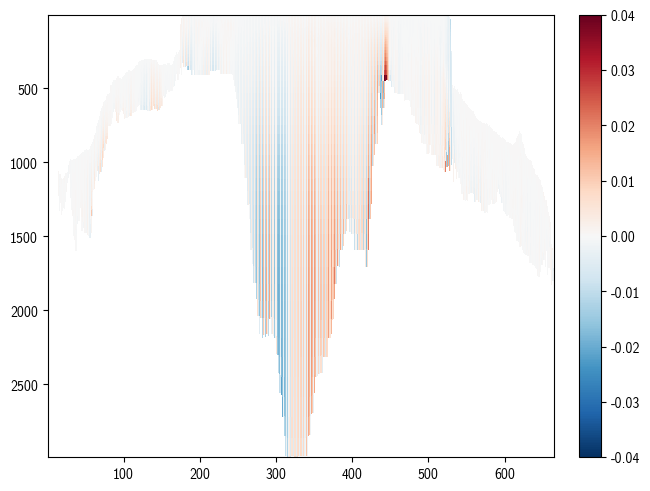

In [17]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)

c =ax.pcolormesh(x_Np1Mp1_outer, y_Np1Mp1_outer, ds_single_transect_masked.swap_dims({'nEdges':'transect_edgesOrdered'}).transportIntoMask_Sv.mean(dim='TWO'), cmap='RdBu_r',
                vmin=-0.04, vmax=0.04) 
ax.invert_yaxis()
fig.colorbar(c, ax=ax)

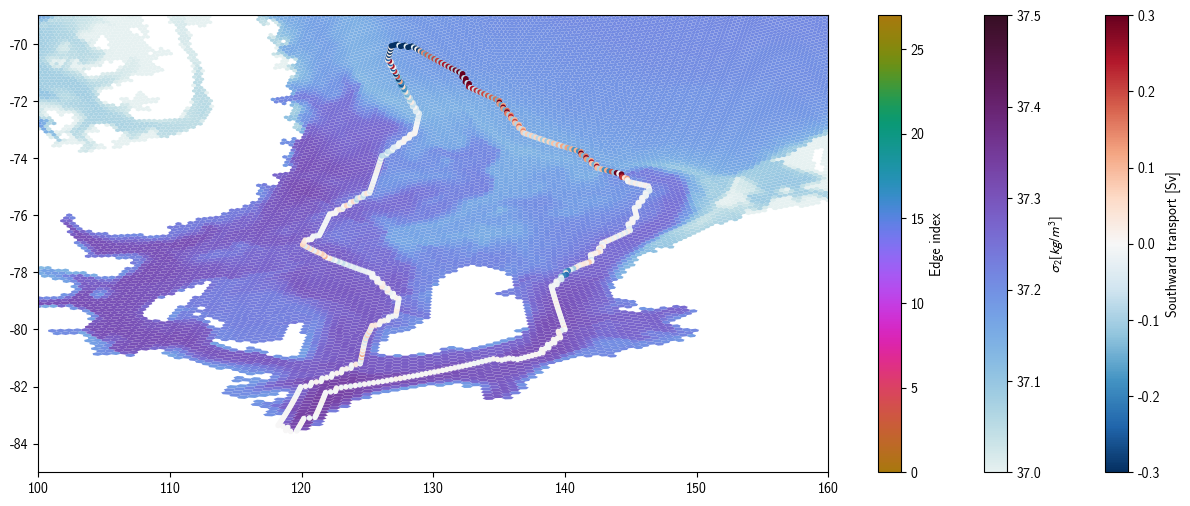

In [18]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True,figsize=(12,5))
c = mosaic.polypcolor(ax, descriptor, bottom_cell_density, cmap = 'cmo.dense', vmin=37, vmax=37.5)

lonEdge = np.rad2deg(ds.lonEdge.isel(nEdges = mps.n_to_xr_idx(ds_single_transect_masked.indexToEdgeID))) - 180
latEdge = np.rad2deg(ds.latEdge.isel(nEdges = mps.n_to_xr_idx(ds_single_transect_masked.indexToEdgeID)))

d = ax.scatter(lonEdge, latEdge, c = ds_single_transect_masked.transportIntoMask_Sv.mean(dim='TWO').sum(dim='nVertLevels'),
              cmap='RdBu_r',vmin=-0.3, vmax=0.3, marker='.')

e = ax.scatter(lons,lats,c=np.arange(0,len(lons)), cmap = 'cmo.phase')
# f = mosaic.contour(ax, descriptor, bottom_depth, levels=[0,1000], colors=['white','magenta'])

ax.set_ylim(-85,-69)
ax.set_xlim(100,160)

fig.colorbar(d, ax=ax, label = 'Southward transport [Sv]')
fig.colorbar(c, ax=ax, label = r'$\sigma_2 [kg/m^3]$')
fig.colorbar(e, ax=ax, label = 'Edge index')

## transect across the shelf break

In [ ]:
path = './'
filename = 'Ronne_Filchner_Shelf_Break_SORRM_HR_test0'
geojson_file_name = 'SORRM HR Weddell Sea Region Shelf Break'
tags = 'Southern Ocean'
author = 'Kaila Uyeda'

# across the shelf break
lats = np.array([-70, -70.25, -70.5, -71, -72,  -72.25, -72.25, -72.25, -72.5, -72.75, -73, -73.25, -73.5, -73.75, -73.75, -73.75, -73.75,-74.25, -74.5,
                -74.25, -74.25, -74, -74.25, -74.5, -74.75, -74.5, -74.25, -74, -73.75, -73.5,
                -76, -79, -77])
lons = np.array([121,122,123,125, 126.5, 128.5, 130, 132, 133, 133.5, 134, 135, 136, 137, 138, 139, 140, 142, 143,
                144.5, 146, 147, 148.5, 150.5, 152, 153, 154, 155, 156, 157,
                157, 135, 125]) -180

# ==========================
# These 3 functions are part of the open_transect_from_alg(ds, lats, lons, path, filename, geojson_file_name, tags, author) function

test_edges, test_verts = mps.calculate_transects_multiple_pts(lons, lats, ds)

test_verts_lats, test_verts_lons, dsMasks = mps.transect_from_alg_create_nc(test_verts, 
                                                                                ds, 
                                                                                path,
                                                                                filename, 
                                                                                geojson_file_name,
                                                                                tags, 
                                                                                author)

alg_edges, alg_vertices = mps.find_and_sort_transect_edges_and_vertices(ds,dsMasks)

# ==========================
edges = alg_edges
vertices = alg_vertices
mask = dsMasks

# ==========================

ds_transect_edges_nCells, ds_transect_edges = mps.format_transect_data(ds, edges)
print('calculate_velo_into_mask')
ds_transect_edges = mps.calculate_velo_into_mask(ds_transect_edges, ds, mask, edges, datavariable= 'normalVelocity')
print('calculate_transport_into_mask')
ds_transect_edges = mps.calculate_transport_into_mask(ds_transect_edges)

dsMasks = xr.open_dataset(f'./{filename}_transect_from_alg.nc')

# # attempt to find just a single transect
ds_single_transect = ds_transect_edges.isel(nEdges = slice(220,495), Time=0)

# Properly conduct a .where comparing the maxLevelCell to nVertLevels AND nVertLevelsP1
# select the datavariables that depend on nVertLevels
nVertLevels_datavariables = []
for i in ds_single_transect.data_vars:
    if 'nVertLevels' in ds_single_transect[i].dims:
        nVertLevels_datavariables.append(i)

# create a dataset with nVertLevels dimensions only
ds_single_transect_nVertLevels = ds_single_transect[nVertLevels_datavariables]

# conduct a .where to mask the values below maxLevelCell
ds_single_transect_nVertLevels_masked = ds_single_transect_nVertLevels.where(ds_single_transect.maxLevelCell > ds_single_transect_nVertLevels.nVertLevels)

# ============

# repeat for nVertLevelsP1 datavariables
# select the datavariables that depend on nVertLevelsP1

nVertLevelsP1_datavariables = []
for i in ds_single_transect.data_vars:
    if 'nVertLevelsP1' in ds_single_transect[i].dims:
        nVertLevelsP1_datavariables.append(i)

# create a dataset with nVertLevelsP1 dimensions only
ds_single_transect_nVertLevelsP1 = ds_single_transect[nVertLevelsP1_datavariables]

# conduct a .where to mask the values below maxlevelCell
ds_single_transect_nVertLevelsP1_masked = ds_single_transect_nVertLevelsP1.where(ds_single_transect.maxLevelCell > ds_single_transect_nVertLevelsP1.nVertLevelsP1)

# merge the two datasets
ds_single_transect_masked = xr.merge([ds_single_transect_nVertLevels_masked, ds_single_transect_nVertLevelsP1_masked])

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True, figsize=(12,5))

c = mosaic.polypcolor(ax, descriptor, bottom_cell_density, cmap = 'cmo.dense', vmin=37, vmax=37.5)
d = mosaic.contour(ax, descriptor, bottom_depth, levels=[0,1000], colors=['white','magenta'])

ax.set_ylim(-90,-60)

fig.colorbar(c, ax=ax, label=r'$\sigma_2$ [kg/m^3]')

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True, figsize=(12,5))

c = mosaic.polypcolor(ax, descriptor, bottom_cell_density, cmap = 'cmo.dense', vmin=37, vmax=37.5)
d = mosaic.contour(ax, descriptor, bottom_depth, levels=[0,1000], colors=['white','magenta'])

ax.set_ylim(-90,-60)

fig.colorbar(c, ax=ax, label=r'$\sigma_2$ [kg/m^3]')

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)
c = mosaic.polypcolor(ax, descriptor, bottom_cell_density, cmap = 'cmo.dense', vmin=37, vmax=37.5)

lonEdge = np.rad2deg(ds.lonEdge.isel(nEdges = edges)) - 180
latEdge = np.rad2deg(ds.latEdge.isel(nEdges = edges))

d = ax.scatter(lonEdge, latEdge, c = np.arange(0,len(edges)))

ax.set_ylim(-85,-69)
ax.set_xlim(100,160)

fig.colorbar(d, ax=ax, label = 'Edge index')
fig.colorbar(c, ax=ax, label=r'$\sigma_2$ [kg/m^3]')

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True, figsize=(7,5))

mask = dsMasks.regionCellMasks.isel(nRegions = 0)

c = mosaic.polypcolor(ax, descriptor, bottom_cell_density, cmap = 'cmo.dense', vmin = 37, vmax=37.5)
a = ax.scatter(np.rad2deg(ds_single_transect.lonEdge)-180, np.rad2deg(ds_single_transect.latEdge), marker = '.',
              c = ds_single_transect.transect_edgesOrdered)

ax.set_ylim(-85,-69)
ax.set_xlim(100,160)

fig.colorbar(a, ax=ax, label='Edge index single transect')

# fig.suptitle('Ronne-Filchner Ice Shelf (Weddell Sea) Transect \n J transect',fontsize=22)

In [ ]:
# select all the cells inside the mask
mask = dsMasks
xr_cells_inside, ignore_xr_edges_inside, ignore_xr_vertices_inside = mps.xr_inside_mask_info(ds,mask)

# identify cells on transect_edges
ds_single_transect = ds_transect_edges.isel(nEdges = slice(220,495), Time=0)

n_cellsOnTransect = ds_single_transect_masked.cellsOnEdge
xr_cellsOnTransect = mps.n_to_xr_idx(n_cellsOnTransect).transpose('nEdges','TWO')

# for each xr_cellsOnTransect value, determine which cell is inside the mask
xr_transect_cells_inside_mask_ordered_raw = np.array([])
xr_transect_cells_outside_mask_ordered_raw = np.array([])

for i in range(0,len(xr_cellsOnTransect.nEdges)):
    # cell on transect edge that is inside mask
    xr_transect_cell_inside_mask = np.intersect1d(xr_cellsOnTransect[i], xr_cells_inside)

    # cell on transect edge that is outside mask
    xr_transect_cell_outside_mask = np.setxor1d(xr_cellsOnTransect[i], xr_transect_cell_inside_mask)

    # append the arrays
    xr_transect_cells_inside_mask_ordered_raw = np.append(xr_transect_cells_inside_mask_ordered_raw, xr_transect_cell_inside_mask)
    xr_transect_cells_outside_mask_ordered_raw = np.append(xr_transect_cells_outside_mask_ordered_raw, xr_transect_cell_outside_mask)

# remove any duplicate values in the array (e.g., if the cell was used once, do not use it again
values, sorted_indices = np.unique(xr_transect_cells_inside_mask_ordered_raw, return_index = True)
xr_transect_cells_inside_mask_ordered = np.int32(xr_transect_cells_inside_mask_ordered_raw[np.sort([sorted_indices])].flatten())

values, sorted_indices = np.unique(xr_transect_cells_outside_mask_ordered_raw, return_index = True)
xr_transect_cells_outside_mask_ordered = np.int32(xr_transect_cells_outside_mask_ordered_raw[np.sort([sorted_indices])].flatten())


## identify transect inside cells
ds_single_transect_insideCells = ds.isel(nCells = xr_transect_cells_inside_mask_ordered, Time=0)

# assign order to nCells
ds_single_transect_insideCells = ds.isel(nCells = xr_transect_cells_inside_mask_ordered, Time=0)

# assign order to nCells
ds_single_transect_insideCells['transect_cellsInsideOrdered'] = xr.DataArray(np.arange(0,xr_transect_cells_inside_mask_ordered.size), dims = 'nCells')

x_center, y_center = pcolormesh_plot(ds_single_transect_insideCells)
x_P1, y_P1 = pcolormesh_plot(ds_single_transect_insideCells, on_nVertLevelsP1=True)

In [ ]:
fig, ax = plt.subplots(nrows = 1, ncols = 3, constrained_layout=True, figsize = (15,4))

iceAreaCell = ds_single_transect_insideCells.iceAreaCell.swap_dims({'nCells' : 'transect_cellsInsideOrdered'})
transect_cellsInsideOrdered = ds_single_transect_insideCells.transect_cellsInsideOrdered

a = ax[0].pcolormesh(x_center, y_center, ds_single_transect_insideCells.density, cmap='cmo.dense',vmin=1027, vmax=1044)
ax[0].set_title(r'Density $[kg m^{-3}]$',fontsize=18)
fig.colorbar(a, ax=ax[0])

b = ax[1].pcolormesh(x_center, y_center, ds_single_transect_insideCells.salinity, cmap = 'cmo.haline', vmin=32.5, vmax=34.8)
ax[1].set_title(r'Salinity $[g/kg]$',fontsize=18)
ax[1].set_yticks([])
fig.colorbar(b, ax=ax[1])

c = ax[2].pcolormesh(x_center, y_center, ds_single_transect_insideCells.temperature, cmap = 'cmo.thermal', vmin=-2.5, vmax=1)
ax[2].set_title(r'Temperature $[^\circ C]$',fontsize=18)
ax[2].set_yticks([])
fig.colorbar(c, ax=ax[2])

for i in range(0,3):
    ax[i].invert_yaxis()

fig.supxlabel('transect_cellsInsideOrdered',fontsize=18)
fig.supylabel('Depth [m]',fontsize=18)
fig.suptitle(f'{month} Ronne-Filchner Ice Shelf',fontsize=22)

In [ ]:
fig, ax = plt.subplots(nrows = 1, ncols = 3, constrained_layout=True, figsize = (15,4))

iceAreaCell = ds_single_transect_insideCells.iceAreaCell.swap_dims({'nCells' : 'transect_cellsInsideOrdered'})
transect_cellsInsideOrdered = ds_single_transect_insideCells.transect_cellsInsideOrdered

a = ax[0].pcolormesh(x_center, y_center, ds_single_transect_insideCells.sigma_2, cmap='cmo.dense')
ax[0].set_title(r'Potential Density $[kg m^{-3}]$',fontsize=18)
fig.colorbar(a, ax=ax[0])

b = ax[1].pcolormesh(x_center, y_center, ds_single_transect_insideCells.salinity, cmap = 'cmo.haline', vmin=32.5, vmax=34.8)
ax[1].set_title(r'Salinity $[g/kg]$',fontsize=18)
ax[1].set_yticks([])
fig.colorbar(b, ax=ax[1])

c = ax[2].pcolormesh(x_center, y_center, ds_single_transect_insideCells.temperature, cmap = 'cmo.thermal', vmin=-2.5, vmax=1)
ax[2].set_title(r'Temperature $[^\circ C]$',fontsize=18)
ax[2].set_yticks([])
fig.colorbar(c, ax=ax[2])

for i in range(0,3):
    ax[i].invert_yaxis()

fig.supxlabel('transect_cellsInsideOrdered',fontsize=18)
fig.supylabel('Depth [m]',fontsize=18)
fig.suptitle(f'{month} Ronne-Filchner Ice Shelf',fontsize=22)

In [ ]:
# for pcolormesh, the dimensions of x-array and y-array must be size (N+1, M+1), where the color-array is of size (N,M)
## X ARRAY (nEdges)
# for nVertLevels = M+1, we can just use broadcast_like z_P1, which already has a length of M+1
x_Mp1_raw = ds_single_transect_masked.transect_edgesOrdered.broadcast_like(ds_single_transect_masked.z_P1)

# since we are on edges with a TWO dimension, take the mean over TWO (all values for TWO=0 and TWO=1 should be the same anyways)
x_Mp1 = x_Mp1_raw.mean(dim='TWO')

# for nEdges = N, we need to add an additioanl row
# we need to expand nEdges to a size of len(nEdges) + 1 = N+1 to make a pcolormesh

x_Np1Mp1 = xr.concat([x_Mp1, x_Mp1.isel(nEdges =-1) + 1], dim='nEdges')

# then we need to stagger the actual nEdge values to represent the "edge" of the nEdges
x_Np1Mp1_outer = x_Np1Mp1 + 0.5

## Y ARRAY (z_P1)

# since we are on edges with a TWO dimension, take the mean over TWO
# note that this time, the values for TWO=0 and TWO=1 may not be the same. e.g., you can have a NaN land cell and an ocean cell next to each other
# note that skipna = True here, so edges along land have the depth of the ocean edge
# for nVertLevels = M+1, we can use z_P1 instead (again). This also ensures that we are already on outer coords
y_Mp1_outer = ds_single_transect_masked.z_P1.mean(dim='TWO').transpose('nEdges','nVertLevelsP1')

# add one additional nEdge
y_Np1Mp1_outer = xr.concat([y_Mp1_outer, y_Mp1_outer.isel(nEdges=-1) + 1], dim ='nEdges')

# ffill along the nVertLevels dimension
y_Np1Mp1_outer = y_Np1Mp1_outer.ffill(dim='nVertLevelsP1')

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)

c =ax.pcolormesh(x_Np1Mp1_outer, y_Np1Mp1_outer, ds_single_transect_masked.swap_dims({'nEdges':'transect_edgesOrdered'}).transportIntoMask_Sv.mean(dim='TWO'), cmap='RdBu_r',
                vmin=-0.04, vmax=0.04) 
ax.invert_yaxis()
fig.colorbar(c, ax=ax)

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)
c = mosaic.polypcolor(ax, descriptor, bottom_depth, cmap = 'cmo.deep', vmax=3000)

lonEdge = np.rad2deg(ds.lonEdge.isel(nEdges = mps.n_to_xr_idx(ds_single_transect_masked.indexToEdgeID))) - 180
latEdge = np.rad2deg(ds.latEdge.isel(nEdges = mps.n_to_xr_idx(ds_single_transect_masked.indexToEdgeID)))

d = ax.scatter(lonEdge, latEdge, c = ds_single_transect_masked.transportIntoMask_Sv.mean(dim='TWO').sum(dim='nVertLevels'),
              cmap='RdBu_r',vmin=-0.3, vmax=0.3, marker='.')

lons = np.array([120.5, 121, 123,   130, 137, 140, 139.5, 140, 143, 145.5, 146.5,   144, 143.5, 143.25, 143, 
                     141, 135, 132, 127,   129,   126, 122, 120, 127.5, 125, 124.5, 120, 119]) # + 180 
lats = np.array([-85,   -83, -82, -81.5, -81, -80,   -79, -78, -77,   -76,   -75, -74.5,  -74.4, -74.5, -74.4, 
                  -73.75, -72, -71, -70, -72.5,   -74, -76, -77,   -79, -80, -80.5, -82, -83])

e = ax.scatter(lons,lats,c=np.arange(0,len(lons)), cmap = 'cmo.phase')

ax.set_ylim(-85,-69)
ax.set_xlim(100,160)

fig.colorbar(d, ax=ax, label = 'Southward transport [Sv]')
fig.colorbar(c, ax=ax, label = r'Bottom depth [m]')
fig.colorbar(e, ax=ax, label = 'Edge index')

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)
c = mosaic.polypcolor(ax, descriptor, bottom_cell_density, cmap = 'cmo.dense', vmin=37, vmax=37.5)

lonEdge = np.rad2deg(ds.lonEdge.isel(nEdges = mps.n_to_xr_idx(ds_single_transect_masked.indexToEdgeID))) - 180
latEdge = np.rad2deg(ds.latEdge.isel(nEdges = mps.n_to_xr_idx(ds_single_transect_masked.indexToEdgeID)))

d = ax.scatter(lonEdge, latEdge, c = ds_single_transect_masked.transportIntoMask_Sv.mean(dim='TWO').sum(dim='nVertLevels'),
              cmap='RdBu_r',vmin=-0.3, vmax=0.3, marker='.')

e = ax.scatter(lons,lats,c=np.arange(0,len(lons)), cmap = 'cmo.phase')
f = mosaic.contour(ax, descriptor, bottom_depth, levels=[0,1000], colors=['white','magenta'])

ax.set_ylim(-85,-69)
ax.set_xlim(100,160)

fig.colorbar(d, ax=ax, label = 'Southward transport [Sv]')
fig.colorbar(c, ax=ax, label = r'$\sigma_2 [kg/m^3]$')
fig.colorbar(e, ax=ax, label = 'Edge index')

In [ ]:
# only get cells where the bottom_depth is between 995 and 1000
isobath_1000m = bottom_depth.where((bottom_depth < 1010) & (bottom_depth > 990)).dropna(dim='nCells',how='all')

In [ ]:
fig,ax = plt.subplots(nrows=1,ncols=1, constrained_layout=True)

lonCell = np.rad2deg(ds.lonCell.isel(nCells = mps.n_to_xr_idx(isobath_1000m.indexToCellID))) - 180
latCell = np.rad2deg(ds.latCell.isel(nCells = mps.n_to_xr_idx(isobath_1000m.indexToCellID)))

d = ax.scatter(lonCell, latCell)

e = mosaic.polypcolor(ax, descriptor, bottom_depth, cmap = 'cmo.deep')
f = mosaic.contour(ax,descriptor, bottom_depth, levels=[0,1000], colors=['white','magenta'])

In [ ]:
BREAAAAAK

In [ ]:
lons = np.array([120.5, 121, 123,   130, 137, 140, 139.5, 140, 143, 145.5, 146.5,   144, 143.5, 143.25, 143, 
                     141,    137,   133,   129,   126, 122, 120, 127.5, 125, 124.5, 124]) + 180 
lats = np.array([-85,   -83, -82, -81.5, -81, -80,   -79, -78, -77,   -76,   -75, -74.5,  -74.4, -74.5, -74.4, 
                  -73.75, -73.75, -72.5,   -72.5, -74, -76, -77, -79,   -80, -80.5, -81])

test_edges, test_verts = mps.calculate_transects_multiple_pts(lons, lats, ds)

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)
c = mosaic.polypcolor(ax, descriptor, bottom_depth, cmap = 'cmo.deep', vmax=3000)

lonEdge = np.rad2deg(ds.lonEdge.isel(nEdges =test_edges)) - 180
latEdge = np.rad2deg(ds.latEdge.isel(nEdges =test_edges))

d = ax.scatter(lonEdge, latEdge, c = np.arange(0,len(test_edges)),marker='.')

ax.scatter(lons,lats, color='magenta',marker='.')

ax.set_ylim(-85,-69)
ax.set_xlim(100,160)

fig.colorbar(d, ax=ax, label = 'Edge index')
fig.colorbar(c, ax=ax, label = r'Density [$kg/m^3$]')

In [ ]:
%whos function

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)

lonEdge = np.rad2deg(ds.lonEdge.isel(nEdges = test_edges)) - 180
latEdge = np.rad2deg(ds.latEdge.isel(nEdges = test_edges))

mosaic.polypcolor(ax, descriptor, ds.iceAreaCell, cmap='cmo.ice')
b = ax.scatter(lonEdge, latEdge, c= np.arange(0,len(test_edges)), cmap='cmo.speed', marker='.')
ax.set_ylim(-85,-70)
ax.set_xlim(100,160)

fig.colorbar(b, ax=ax, label='test_edges order')
fig.suptitle(f'transect and sea ice in {month}')

## Plot the densest water contours

In [ ]:
find_var_in_ds(ds, 'max')

In [ ]:
ds.refBottomDepth

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)

c = mosaic.polypcolor(ax, descriptor, bottom_cell_density, cmap = 'cmo.dense')

fig.colorbar(c, ax=ax, label = 'densest water')
fig.suptitle(f'Density at bottom cell, {month}')

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)

c = mosaic.polypcolor(ax, descriptor, bottom_cell_density, cmap = 'cmo.dense', vmin=1020, vmax=1040)

fig.colorbar(c, ax=ax, label = 'densest water')
fig.suptitle(f'Density at bottom cell, {month}')

b = ax.scatter(lonEdge, latEdge, c= np.arange(0,len(test_edges)), cmap='cmo.speed', marker='.')

ax.set_ylim(-85,-70)
ax.set_xlim(100,160)

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)

c = mosaic.polypcolor(ax, descriptor, bottom_depth, cmap = 'cmo.deep')
ax.set_ylim(-85,-70)
ax.set_xlim(100,160)

fig.colorbar(c, ax=ax, label = 'depth')
fig.suptitle(f'Depth of ocean; RF shelf')

b = ax.scatter(lonEdge, latEdge, c= np.arange(0,len(test_edges)), cmap='cmo.speed', marker='.')

In [ ]:
ds.potentialDensity

In [ ]:
find_var_in_ds(ds,'igma')

In [ ]:
find_var_in_ds(ds,'ensity')

In [ ]:
bottom_cell_potential_density = ds.potentialDensity.isel(nVertLevels = ds.maxLevelCell-1, Time=0)

fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)

c = mosaic.polypcolor(ax, descriptor, bottom_cell_potential_density, cmap = 'cmo.dense', vmin = 1027.25, vmax=1028)
ax.set_ylim(-85,-70)
ax.set_xlim(100,160)

fig.colorbar(c, ax=ax, label = 'densest water')
fig.suptitle(f'Potential Density at bottom cell, {month}')

## plot of bottom bathymetry

In [ ]:
ds.zMid.isel(nVertLevels=ds.maxLevelCell -1, Time=0)

In [ ]:
bottom_depth = ds.zMid.isel(nVertLevels=ds.maxLevelCell -1, Time=0)

fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)

c = mosaic.polypcolor(ax, descriptor, bottom_depth, cmap = 'cmo.deep')
# ax.set_ylim(-85,-70)
# ax.set_xlim(100,160)

fig.colorbar(c, ax=ax, label = 'depth')
fig.suptitle(f'Depth of ocean')

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, constrained_layout=True)

c = mosaic.polypcolor(ax, descriptor, bottom_depth, cmap = 'cmo.deep')
ax.set_ylim(-85,-70)
ax.set_xlim(100,160)

fig.colorbar(c, ax=ax, label = 'depth')
fig.suptitle(f'Depth of ocean; RF shelf')

In [ ]:
%whos function

In [ ]:
# fig = plt.figure(constrained_layout = True, figsize = (12,7))
# ax1 = fig.add_subplot(1, 2, 1)
# ax2 = fig.add_subplot(1, 2, 2, projection = stereo_projection)
# mask = dsMasks.regionCellMasks.isel(nRegions = 0)

# # LHS, default mercator on cartersian axis
# mosaic.polypcolor(ax1, descriptor, mask, cmap = 'cool')
# ax1.scatter(np.rad2deg(ds_transect_edges.lonEdge)-180, np.rad2deg(ds_transect_edges.latEdge), marker = '.', 
#            c = ds_transect_edges.transportIntoMask_Sv.isel(Time=0).sum(dim='nVertLevels'), cmap='RdBu_r')
# ax1.set_xlim(100,180)
# ax1.set_ylim(-90,-60)

# # RHS, polar-stereographic
# stereo_projection = ccrs.SouthPolarStereo()
# stereo_transform = ccrs.PlateCarree()

# c = mosaic.polypcolor(ax2, stereo_descriptor, mask, cmap  = 'cool')
# mosaic.coastlines(ax2, stereo_descriptor, color ='gray')
# ax2.scatter(np.rad2deg(ds_transect_edges.lonEdge), np.rad2deg(ds_transect_edges.latEdge), marker = '.', 
#        c = ds_transect_edges.transportIntoMask_Sv.isel(Time=0).sum(dim='nVertLevels'), cmap='RdBu_r', transform = ccrs.PlateCarree())
# ax2.set_extent([-180, 180, -90, -65],
#                  crs = ccrs.PlateCarree())

# verts, circle = circular_polar_map()

# ax2.set_boundary(circle, transform=ax2.transAxes)
# gl = ax2.gridlines(linewidth=0.75,color="black",alpha=0.5,linestyle="dotted",draw_labels=True)

In [ ]:
# path = './'
# filename = 'Ronne_Filchner_Slope_SORRM_F04_attempt0'
# geojson_file_name = 'SORRM HR Weddell Sea Region'
# tags = 'Southern Ocean'
# author = 'Kaila Uyeda'

# lons = np.array([120.5, 121, 130, 137, 140, 143, 145, 150, 142, 125]) + 180 
# lats = np.array([-85, -82, -81.25, -81, -80, -77, -75, -73, -73, -76]) 

# # ==========================
# # These 3 functions are part of the open_transect_from_alg(ds, lats, lons, path, filename, geojson_file_name, tags, author) function

# test_edges, test_verts = mps.calculate_transects_multiple_pts(lons, lats, ds)

# # test_verts_lats, test_verts_lons, dsMasks = mps.transect_from_alg_create_nc(test_verts, 
# #                                                                                 ds, 
# #                                                                                 path,
# #                                                                                 filename, 
# #                                                                                 geojson_file_name,
# #                                                                                 tags, 
# #                                                                                 author)

# # alg_edges, alg_vertices = mps.find_and_sort_transect_edges_and_vertices(ds,dsMasks)

# # # ==========================
# # edges = alg_edges
# # vertices = alg_vertices
# # mask = dsMasks

# # # ==========================

# # ds_transect_edges_nCells, ds_transect_edges = mps.format_transect_data(ds, edges)
# # print('calculate_velo_into_mask')
# # ds_transect_edges = mps.calculate_velo_into_mask(ds_transect_edges, ds, mask, edges, datavariable= 'normalVelocity')
# # print('calculate_transport_into_mask')
# # ds_transect_edges = mps.calculate_transport_into_mask(ds_transect_edges)

# # dsMasks = xr.open_dataset(f'./{filename}_transect_from_alg.nc')

# # # attempt to find just a single transect
# # ds_single_transect = ds_transect_edges.isel(nEdges = slice(290,541), Time=0)
# # ds_single_transect_masked = ds_single_transect.where(ds_single_transect.maxLevelCell > ds_single_transect.nVertLevels)